# 2017 — VQ-VAE: Discrete Latent Codes

**Paper:** Aäron van den Oord, Oriol Vinyals & Koray Kavukcuoglu, *"Neural Discrete Representation Learning"*, NeurIPS (2017). Follow-up: VQ-VAE-2 (Razavi et al., 2019).

A VAE (notebook 19) compresses an image into a continuous vector. The VQ-VAE compresses it into a small grid of **discrete codes**, integers drawn from a learned **codebook** $\{e_1,\dots,e_K\}$:

1. An encoder maps the image to a grid of vectors $z_e(x)$.
2. **Vector quantization:** each vector is replaced by its nearest codebook entry, $z_q = e_k$ with $k=\arg\min_j \lVert z_e - e_j\rVert$.
3. A decoder reconstructs the image from $z_q$.

The $\arg\min$ has no gradient, so the decoder's gradient is copied straight through to the encoder (the **straight-through estimator**). Two extra terms train the codebook and keep the encoder committed to it:

$$\mathcal L = \lVert x - \hat x\rVert^2 + \lVert \operatorname{sg}[z_e] - e\rVert^2 + \beta\,\lVert z_e - \operatorname{sg}[e]\rVert^2$$

where sg is stop-gradient. Why discrete codes matter: an image becomes a short sequence of **tokens**, and an autoregressive model (a PixelCNN in the paper, later a Transformer) can learn a prior over them. That is how DALL·E 1, Parti, Jukebox, neural audio codecs (SoundStream, EnCodec) and the image tokenizers of today's multimodal LLMs work. Latent diffusion (notebook 56) uses the same "compress first, then model the latents" idea.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors(size=16)]

test reconstruction MSE 0.0018
each 16×16 image (256 floats) → 4×4 = 16 tokens from a codebook of 32 = 80 bits
codes in use: 32/32, codebook perplexity 28.7


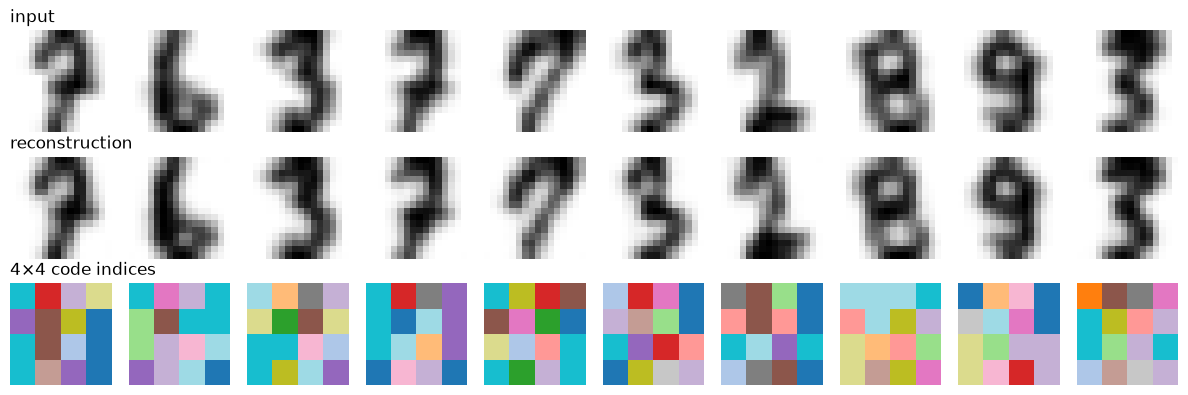

In [3]:
class VQ(nn.Module):
    def __init__(self, K=32, D=16, beta=0.25):
        super().__init__(); self.codebook = nn.Embedding(K, D); self.codebook.weight.data.uniform_(-1 / K, 1 / K); self.beta = beta
    def forward(self, z):                                                    # z: (B, D, H, W)
        B, D, H, W = z.shape
        flat = z.permute(0, 2, 3, 1).reshape(-1, D)
        d = flat.pow(2).sum(1, keepdim=True) - 2 * flat @ self.codebook.weight.T + self.codebook.weight.pow(2).sum(1)
        idx = d.argmin(1)
        zq = self.codebook(idx).view(B, H, W, D).permute(0, 3, 1, 2)
        loss = F.mse_loss(zq, z.detach()) + self.beta * F.mse_loss(z, zq.detach())   # codebook + commitment
        zq = z + (zq - z).detach()                                           # straight-through: forward zq, backward identity
        return zq, loss, idx.view(B, H, W)

class VQVAE(nn.Module):
    def __init__(self, K=32, D=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Conv2d(64, D, 1))   # 16 → 4
        self.vq = VQ(K, D)
        self.dec = nn.Sequential(nn.Conv2d(D, 64, 3, padding=1), nn.ReLU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(32, 1, 4, 2, 1))
    def forward(self, x):
        zq, vq_loss, idx = self.vq(self.enc(x))
        return torch.sigmoid(self.dec(zq)), vq_loss, idx

seed_everything(0)
model = VQVAE().to(device); opt = torch.optim.Adam(model.parameters(), lr=2e-3)
for step in range(3000):
    x = Xtr[torch.randint(0, len(Xtr), (128,), device=device)]
    xh, vq_loss, idx = model(x)
    loss = F.mse_loss(xh, x) + vq_loss; opt.zero_grad(); loss.backward(); opt.step()
model.eval()
with torch.no_grad():
    xh, _, idx = model(Xte)
    usage = torch.bincount(idx.flatten(), minlength=32).float(); p = usage / usage.sum()
    perplexity = torch.exp(-(p[p > 0] * p[p > 0].log()).sum()).item()
print(f"test reconstruction MSE {F.mse_loss(xh, Xte).item():.4f}")
print(f"each 16×16 image (256 floats) → 4×4 = 16 tokens from a codebook of 32 = {16 * 5} bits")
print(f"codes in use: {(usage > 0).sum().item()}/32, codebook perplexity {perplexity:.1f}")
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for i in range(10):
    axes[0, i].imshow(Xte[i, 0].cpu(), cmap="gray_r"); axes[1, i].imshow(xh[i, 0].cpu(), cmap="gray_r")
    axes[2, i].imshow(idx[i].cpu(), cmap="tab20", vmin=0, vmax=31)
for a in axes.flat: a.axis("off")
axes[0, 0].set_title("input", loc="left"); axes[1, 0].set_title("reconstruction", loc="left"); axes[2, 0].set_title("4×4 code indices", loc="left")
plt.tight_layout(); plt.show()

## A prior over the tokens: generating new digits
The VQ-VAE itself cannot generate; its latent is just a grid of integers. Train a small **class-conditional Transformer** to predict the 16 code tokens of a digit one at a time (row by row), sample new token grids, and decode them with the VQ-VAE decoder. This two-stage recipe (tokenize, then model the tokens) is the one behind DALL·E 1 and Parti.

/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_935/961162538.py:6: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tf = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True, norm_first=True), n_layers)


prior loss 0.516 nats/token (uniform would be 3.466)


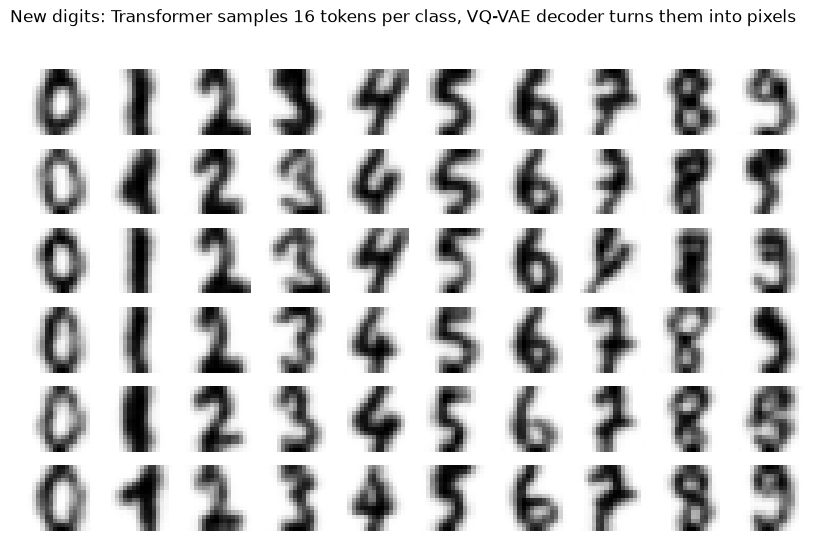

In [4]:
with torch.no_grad(): codes = model(Xtr)[2].flatten(1)                     # (N, 16) integer tokens
class Prior(nn.Module):
    def __init__(self, K=32, d=128, n_layers=3, heads=4):
        super().__init__()
        self.tok, self.cls, self.pos = nn.Embedding(K + 1, d), nn.Embedding(10, d), nn.Parameter(torch.randn(17, d) * 0.02)
        self.tf = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True, norm_first=True), n_layers)
        self.head = nn.Linear(d, K)
    def forward(self, seq, y):                                               # seq: (B, T) codes, prefixed by a start token K
        h = self.tok(seq) + self.pos[:seq.shape[1]] + self.cls(y)[:, None]
        mask = nn.Transformer.generate_square_subsequent_mask(seq.shape[1], device=seq.device)
        return self.head(self.tf(h, mask=mask, is_causal=True))
seed_everything(0)
prior = Prior().to(device); opt = torch.optim.AdamW(prior.parameters(), lr=1e-3, weight_decay=0.01)
start = torch.full((len(codes), 1), 32, device=device)
inp = torch.cat([start, codes[:, :-1]], 1)
for step in range(2500):
    b = torch.randint(0, len(codes), (128,), device=device)
    loss = F.cross_entropy(prior(inp[b], ytr[b]).reshape(-1, 32), codes[b].reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
print(f"prior loss {loss.item():.3f} nats/token (uniform would be {math.log(32):.3f})")
prior.eval()
@torch.no_grad()
def sample(y, temp=1.0):
    seq = torch.full((len(y), 1), 32, device=device)
    for t in range(16):
        p = F.softmax(prior(seq, y)[:, -1] / temp, -1); seq = torch.cat([seq, torch.multinomial(p, 1)], 1)
    zq = model.vq.codebook(seq[:, 1:]).view(len(y), 4, 4, -1).permute(0, 3, 1, 2)
    return torch.sigmoid(model.dec(zq))
seed_everything(1)
imgs = sample(torch.arange(10, device=device).repeat_interleave(6))
fig, axes = plt.subplots(6, 10, figsize=(10, 6))
for i in range(60): axes[i % 6, i // 6].imshow(imgs[i, 0].cpu(), cmap="gray_r"); axes[i % 6, i // 6].axis("off")
plt.suptitle("New digits: Transformer samples 16 tokens per class, VQ-VAE decoder turns them into pixels"); plt.show()

## Takeaways
- **Images (and audio) as tokens.** Vector quantization turns a continuous signal into a short sequence of integers that a sequence model can learn, just like text.
- **Straight-through estimation** lets gradients pass a non-differentiable $\arg\min$; the codebook and commitment terms keep encoder outputs and codes together. Codebook collapse (few codes used) is the classic failure mode; EMA codebook updates, code resets and lookup-free / finite scalar quantization (FSQ, 2023) are common fixes.
- **Two-stage generation** (a tokenizer, then a prior over tokens) is the template for DALL·E 1, Parti, MaskGIT, and the discrete image/audio tokens inside modern multimodal LLMs.